# 01 · Preprocesamiento

De la descarga cruda de la tienda y la API de Steam (`data/raw/`) a las tablas limpias de `data/processed/`. Cada decisión va con su motivo. La lógica vive en `src/radar/preparacion.py` (la misma que ejecuta `python -m radar.preparacion`); aquí se recorre paso a paso para ver qué hace con los datos reales.

In [1]:
import json

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

from radar import config
from radar import preparacion as prep

plt.rcParams.update({"figure.figsize": (8, 4), "axes.grid": True, "grid.alpha": 0.3})
pd.set_option("display.max_columns", 30)

## 1. Lo que llega de la ingesta

In [2]:
candidatos = json.loads(
    (config.DIR_RAW / "candidatos.json").read_text(encoding="utf-8")
)
fichas, resenas = prep.cargar_crudo()
descartadas = sum(1 for f in fichas if f.get("descartada"))
print(f"Candidatos del buscador de la tienda: {len(candidatos)}")
print(f"Fichas descargadas: {len(fichas)} ({descartadas} no son juegos o no existen)")
print(f"Juegos con reseñas descargadas (lanzados en la ventana): {len(resenas)}")

Candidatos del buscador de la tienda: 4069
Fichas descargadas: 4069 (0 no son juegos o no existen)
Juegos con reseñas descargadas (lanzados en la ventana): 4069


In [3]:
# La API sin clave solo devuelve reseñas en inglés; el buscador de la tienda cuenta todos los idiomas.
en_tienda = {c["appid"]: c["resenas_tienda"] for c in candidatos}
cuota = pd.Series(
    [
        min(1, r["descargadas"] / en_tienda[r["appid"]])
        for r in resenas
        if en_tienda.get(r["appid"])
    ]
)
print("Reseñas en inglés sobre el total de cada juego:")
cuota.describe(percentiles=[0.1, 0.25, 0.5, 0.75, 0.9]).round(2)

Reseñas en inglés sobre el total de cada juego:


count    4069.00
mean        0.41
std         0.33
min         0.00
10%         0.00
25%         0.07
50%         0.40
75%         0.69
90%         0.90
max         1.00
dtype: float64

**Conclusión.** El buscador de la tienda dio 4.069 juegos lanzados entre el 29-10-2025 y el 09-09-2026 con entre 50 y 10.000 reseñas; todos tienen ficha y reseñas descargadas. La API pública solo sirve reseñas en inglés: en el juego mediano son el 40 % del total, pero en uno de cada cuatro no llegan al 7 % (juegos cuyo público escribe sobre todo en otros idiomas). Por eso todo el proyecto mide reseñas en inglés, en la entrada del radar y en el objetivo, y la app lo pide así.

## 2. Tipos y formatos

La fecha de la tienda llega como texto en inglés (`Sep 17, 2020`) y el precio en céntimos. La ingesta ya los convierte; aquí se comprueba que el resultado tiene el tipo correcto y valores con sentido.

In [4]:
juegos = prep.construir_juegos(fichas, resenas)
print(juegos.dtypes[["fecha_lanzamiento", "precio_usd", "gratis", "resenas_api"]])
juegos[["fecha_lanzamiento", "precio_usd", "resenas_api"]].describe()

fecha_lanzamiento    datetime64[us]
precio_usd                  float64
gratis                         bool
resenas_api                   int64
dtype: object


,fecha_lanzamiento,precio_usd,resenas_api
count,4069,4065.000000,4069.000000
mean,2026-04-09 09:41:26.999262,11.425048,334.149422
min,2025-10-29 00:00:00,0.000000,0.000000
25%,2026-01-21 00:00:00,4.990000,14.000000
50%,2026-04-13 00:00:00,9.990000,58.000000
75%,2026-07-10 00:00:00,14.990000,199.000000
max,2026-09-09 00:00:00,79.990000,9957.000000
std,NaN,10.565403,980.983601


**Conclusión.** Fechas como `datetime`, precio en dólares con decimales y conteos enteros. El precio va de 0 a 79,99 $ con mediana de 9,99 $: no hay valores imposibles. `resenas_api` llega a 0 en algún juego aunque el buscador mostraba 50 o más: son juegos sin reseñas en inglés, que la exclusión del apartado 5 recoge.

## 3. Nulos y duplicados

In [5]:
print("appid duplicados:", juegos["appid"].duplicated().sum())
print("Nombres repetidos:", juegos["nombre"].duplicated().sum())
juegos.isna().sum().loc[lambda s: s > 0]

appid duplicados: 0
Nombres repetidos: 2


precio_usd      4
editor          3
banda_precio    4
dtype: int64

In [6]:
juegos[juegos["nombre"].duplicated(keep=False)].sort_values("nombre")[
    ["appid", "nombre", "fecha_lanzamiento", "desarrollador"]
]

,appid,nombre,fecha_lanzamiento,desarrollador
3119,4218680,Bird Game 3,2026-05-25,Birdgame Studios
3121,4219010,Bird Game 3,2026-04-03,Crashout Games
1305,3179050,Piece by Piece,2026-03-11,Gamkat
1383,3249380,Piece by Piece,2026-03-13,Neon Polygons


**Conclusión.** No hay `appid` duplicados. Los dos nombres repetidos son juegos distintos (otro estudio, otra fecha), así que se conservan: la clave es el `appid`, nunca el nombre. Faltan 4 precios (juegos sin precio en dólares en la tienda) y 3 editores; el editor no se usa en el modelo y los 4 sin precio se excluyen, porque el precio es una de las pocas variables previas al lanzamiento.

## 4. Unión de fuentes: reseñas por día desde el lanzamiento

Cada reseña se sitúa en el día relativo a la fecha oficial de lanzamiento (día 0 = el día que sale). Valores negativos = reseñas anteriores a la fecha oficial.

In [7]:
diarias = prep.construir_diarias(resenas, juegos)
print(f"{len(diarias):,} filas juego-día")
previas = diarias[diarias["dia"] < 0].groupby("appid")["resenas"].sum()
totales = diarias.groupby("appid")["resenas"].sum()
pct_previas = (previas / totales).reindex(totales.index).fillna(0)
print(f"Juegos con alguna reseña antes de la fecha oficial: {(pct_previas > 0).sum()}")
print(
    f"... con más del {prep.MAX_PCT_PREVIAS:.0%} de sus reseñas antes: {(pct_previas > prep.MAX_PCT_PREVIAS).sum()}"
)

208,126 filas juego-día
Juegos con alguna reseña antes de la fecha oficial: 411
... con más del 5% de sus reseñas antes: 373


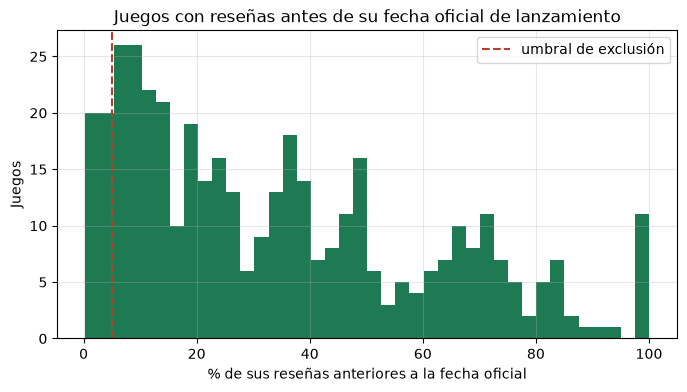

In [8]:
fig, ax = plt.subplots()
ax.hist(pct_previas[pct_previas > 0] * 100, bins=40, color="#1e7a52")
ax.axvline(
    prep.MAX_PCT_PREVIAS * 100, color="#b3402a", ls="--", label="umbral de exclusión"
)
ax.set(
    title="Juegos con reseñas antes de su fecha oficial de lanzamiento",
    xlabel="% de sus reseñas anteriores a la fecha oficial",
    ylabel="Juegos",
)
ax.legend();

**Conclusión.** 411 juegos tienen alguna reseña antes de su fecha oficial y 373 superan el 5 %. Son juegos que salieron de acceso anticipado o tuvieron una fase pública con reseñas: su día 0 no es un lanzamiento desde cero y la curva de sus primeros días no se parece a la de un estreno. Se excluyen con ese umbral; por debajo, unas pocas reseñas de prensa o de claves anticipadas no cambian la curva.

## 5. Exclusiones

In [9]:
juegos = prep.marcar_aptos(juegos, diarias)
juegos["estado"].value_counts().to_frame("juegos")

,juegos
estado,
apto,3019
sin_resenas_en_30d,689
fase_previa_publica,357
sin_precio_usd,4


**Conclusión.** Quedan 3.019 juegos aptos de 4.069 (74 %). La exclusión más grande, 689 juegos, son los que no reciben ninguna reseña en inglés en su primer mes: el radar no puede decir nada útil de un juego cuyo público no escribe en inglés, y la app lo explica. 357 tuvieron fase previa pública y 4 no tienen precio en dólares.

## 6. Valores atípicos

El volumen de reseñas tiene una cola muy larga. Se mira en escala logarítmica para decidir si hay errores o solo juegos muy grandes.

count    3019.0
mean      219.7
std       636.6
min         1.0
1%          1.0
25%        19.5
50%        48.0
75%       138.0
99%      3671.9
max      8175.0
Name: resenas_30d, dtype: float64

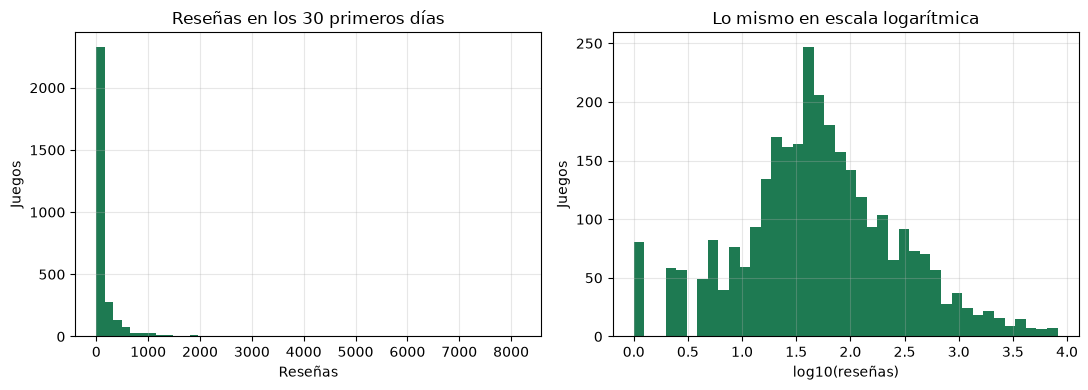

In [10]:
aptos = juegos[juegos["estado"] == "apto"]
fig, axes = plt.subplots(1, 2, figsize=(11, 4))
axes[0].hist(aptos["resenas_30d"], bins=50, color="#1e7a52")
axes[0].set(title="Reseñas en los 30 primeros días", xlabel="Reseñas", ylabel="Juegos")
axes[1].hist(np.log10(aptos["resenas_30d"]), bins=40, color="#1e7a52")
axes[1].set(
    title="Lo mismo en escala logarítmica", xlabel="log10(reseñas)", ylabel="Juegos"
)
plt.tight_layout()
aptos["resenas_30d"].describe(percentiles=[0.01, 0.25, 0.5, 0.75, 0.99]).round(1)

In [11]:
aptos.nlargest(5, "resenas_30d")[
    [
        "nombre",
        "fecha_lanzamiento",
        "precio_usd",
        "genero_principal",
        "resenas_30d",
        "resenas_api",
    ]
]

,nombre,fecha_lanzamiento,precio_usd,genero_principal,resenas_30d,resenas_api
1176,Hell Let Loose: Vietnam,2026-08-13,39.99,Action,8175,8970
1397,Vampire Crawlers: The Turbo Wildcard from Vamp...,2026-04-21,9.99,Action,7106,8538
1037,IRON NEST: Heavy Turret Simulator,2026-08-06,19.99,Action,7065,8159
1420,Mistfall Hunter,2026-07-29,24.99,Action,6693,7615
145,Cairn,2026-01-29,29.99,Action,6675,9910


**Conclusión.** La distribución es muy asimétrica: mediana de 48 reseñas en el primer mes, media de 220 y un 1 % por encima de 3.600. Los juegos más grandes (Hell Let Loose: Vietnam, Vampire Crawlers…) son lanzamientos reales, no errores, así que no se recortan. En escala logarítmica la forma es casi simétrica: el modelo trabaja en log(1 + reseñas), donde un error de «el doble» pesa lo mismo con 20 reseñas que con 2.000.

## 7. Variables nuevas y tabla final

In [12]:
dataset = prep.construir_dataset(juegos, diarias)
print(dataset.shape)
dataset.head()

(3019, 17)


,appid,nombre,fecha_lanzamiento,precio_usd,gratis,banda_precio,genero_principal,es_indie,mes_lanzamiento,dia_semana_lanzamiento,resenas_3d,pct_positivas_3d,resenas_7d,pct_positivas_7d,resenas_14d,pct_positivas_14d,resenas_30d
0,1541370,Ultimate Theater Simulator,2025-10-29,12.99,False,hasta_20,Simulation,False,10,2,39,0.871795,86,0.883721,169,0.893491,242
1,3708660,DOCTOR VISCERA,2025-10-29,7.99,False,hasta_10,Action,True,10,2,5,1.000000,10,1.000000,12,1.000000,16
2,3808860,Strange Dream,2025-10-29,4.99,False,hasta_10,Adventure,True,10,2,1,0.000000,2,0.500000,2,0.500000,2
3,1385340,Orbyss,2025-10-29,14.99,False,hasta_20,Indie,True,10,2,15,0.933333,17,0.941176,22,0.954545,28
4,3022010,Bonanit - A Menorcan Horror Story,2025-10-29,4.99,False,hasta_10,Indie,True,10,2,5,0.600000,12,0.750000,16,0.812500,21


In [13]:
print("Nulos en el dataset del modelo:")
dataset.isna().sum().loc[lambda s: s > 0]

Nulos en el dataset del modelo:


pct_positivas_3d     146
pct_positivas_7d      57
pct_positivas_14d     28
dtype: int64

**Conclusión.** Una fila por juego con las lecturas a 3, 7 y 14 días, el objetivo a 30 días y las variables previas al lanzamiento (precio, banda, género, mes y día de la semana). Los únicos nulos son el porcentaje de positivas cuando aún no hay reseñas (146 juegos el día 3, 28 el día 14): se dejan vacíos y el modelo los imputa con la mediana del entrenamiento, en lugar de inventar un 0 % o un 100 %.

In [14]:
# Mismas salidas que `python -m radar.preparacion`
prep.main();

INFO Juegos: 4069 ({'apto': 3019, 'sin_resenas_en_30d': 689, 'fase_previa_publica': 357, 'sin_precio_usd': 4})


INFO Dataset del radar: 3019 juegos aptos
